# 07 — Validación: cómo estimar el desempeño de forma honesta

**Objetivo:** entender cómo se mide el desempeño de un modelo con datos que
no vio, y qué decide cada elección de la validación. Al terminar deberías
poder explicar:
- por qué el desempeño sobre los datos de entrenamiento no sirve;
- qué es la **validación cruzada estratificada** y por qué se repite;
- qué son las predicciones **fuera de la partición** (*out-of-fold*) y el
  **intervalo de confianza por bootstrap**;
- la diferencia entre validar **por grabación** y **por caso**, y cómo medir
  cuánto pesa la fuga de información con un **experimento de control**.

Usamos un solo modelo, la regresión logística, para que el foco esté en la
validación. En la tesis, la validación principal es **por grabación**; la
validación **por caso** se usa como comparación.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import (LeaveOneGroupOut, StratifiedGroupKFold, StratifiedKFold,
                                     cross_val_predict)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.paths import OUT_DIR

NO_FEATURES = ["file_id", "label", "label_binary"]
REPETICIONES = 20


def cargar(subset):
    df = pd.read_csv(OUT_DIR / f"{subset.lower()}_features.csv")
    X, y = df.drop(columns=NO_FEATURES), df["label_binary"].values
    caso = df["file_id"].str.split("_").str[:2].str.join("_").values   # género_tipo
    return df, X, y, caso


def modelo():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))


datos = {s: cargar(s) for s in ["LS", "HS"]}

## 1. Por qué no alcanza con el desempeño en entrenamiento

Entrenamos con las 50 grabaciones y medimos el AUC **sobre esas mismas 50**:

In [2]:
for subset, (df, X, y, caso) in datos.items():
    m = modelo().fit(X, y)
    print(f"{subset}: AUC sobre los datos de entrenamiento = {roc_auc_score(y, m.predict_proba(X)[:, 1]):.3f}")

LS: AUC sobre los datos de entrenamiento = 1.000
HS: AUC sobre los datos de entrenamiento = 1.000


Da prácticamente perfecto en los dos subconjuntos, incluso en cardíacos, que
sabemos que es difícil. Con 105 features y 50 grabaciones, el modelo puede
"memorizar" cada grabación (**sobreajuste**). Es como evaluar a un alumno con
las mismas preguntas que estudió: no dice nada sobre si entendió. El
desempeño que importa es sobre grabaciones **que el modelo no vio**.

## 2. Validación cruzada estratificada

Con 50 grabaciones no podemos darnos el lujo de apartar muchas para evaluar.
La **validación cruzada de k particiones** (*k-fold*) usa todas:
1. se dividen las grabaciones en k grupos (acá, k = 5, de 10 grabaciones cada uno);
2. se entrena con 4 grupos y se evalúa con el quinto;
3. se repite 5 veces, cambiando el grupo de evaluación, hasta que cada
   grabación fue evaluada **una vez**, por un modelo que no la vio.

**Estratificada** significa que cada grupo mantiene la proporción de clases.
Con solo 12 normales es clave: sin estratificar, un grupo podría quedarse sin
ningún normal.

In [3]:
df, X, y, caso = datos["LS"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
for i, (entrenamiento, evaluacion) in enumerate(cv.split(X, y)):
    print(f"Partición {i + 1}: entrena con {len(entrenamiento)} ({int((y[entrenamiento] == 0).sum())} normales), "
          f"evalúa {len(evaluacion)} ({int((y[evaluacion] == 0).sum())} normales)")

Partición 1: entrena con 40 (9 normales), evalúa 10 (3 normales)
Partición 2: entrena con 40 (9 normales), evalúa 10 (3 normales)
Partición 3: entrena con 40 (10 normales), evalúa 10 (2 normales)
Partición 4: entrena con 40 (10 normales), evalúa 10 (2 normales)
Partición 5: entrena con 40 (10 normales), evalúa 10 (2 normales)


### Predicciones fuera de la partición (*out-of-fold*)

Cada grabación recibe su probabilidad del modelo que **no la usó** para
entrenar. Al final tenemos 50 probabilidades "honestas", y con ellas
calculamos **un** AUC sobre las 50 juntas. Es lo que hace `cross_val_predict`.

¿Por qué no calcular un AUC por partición y promediar? Porque cada partición
tiene 2 o 3 normales: un AUC con tan pocos normales es muy inestable. Juntar
las 50 predicciones da una estimación más estable.

### Repetir con distintos sorteos

Cómo se reparten las grabaciones en las 5 particiones es un sorteo (la
"semilla"). Con pocos datos, el AUC cambia según el sorteo. Por eso conviene
**repetir** la validación con varias semillas y mirar el rango:

In [4]:
def auc_por_grabacion(X, y, semilla):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)
    return roc_auc_score(y, cross_val_predict(modelo(), X, y, cv=cv, method="predict_proba")[:, 1])


aucs_grabacion = {}
for subset, (df, X, y, caso) in datos.items():
    aucs_grabacion[subset] = [auc_por_grabacion(X, y, s) for s in range(REPETICIONES)]
    v = aucs_grabacion[subset]
    print(f"{subset}: AUC por grabación en {REPETICIONES} sorteos: media {np.mean(v):.3f}, "
          f"de {np.min(v):.3f} a {np.max(v):.3f}")

LS: AUC por grabación en 20 sorteos: media 0.998, de 0.991 a 1.000
HS: AUC por grabación en 20 sorteos: media 0.711, de 0.631 a 0.767


En cardíacos, **el mismo modelo con los mismos datos** da un AUC entre ~0,63 y
~0,77 solo por cómo se sortean las particiones. Un único número esconde esa
variabilidad. Por eso conviene reportar la media de varias repeticiones, con
su rango o su intervalo de confianza.

## 3. Intervalo de confianza por bootstrap

El intervalo de confianza responde: *si hubiéramos tenido otra muestra de
grabaciones parecida, ¿cuánto podría cambiar el AUC?* No tenemos otra
muestra, pero podemos **simularla** con el **bootstrap**:
1. tomamos 50 grabaciones **al azar, con reposición**, de nuestras 50 (algunas
   salen repetidas, otras no salen);
2. calculamos el AUC con sus probabilidades fuera de la partición;
3. repetimos 2000 veces;
4. el intervalo del 95 % va del percentil 2,5 al 97,5 de esos 2000 AUC.

In [5]:
def ic_bootstrap(y, prob, n=2000, semilla=0):
    rng = np.random.default_rng(semilla)
    aucs = []
    while len(aucs) < n:
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) == 2:          # hace falta al menos un normal y un patológico
            aucs.append(roc_auc_score(y[i], prob[i]))
    return np.percentile(aucs, [2.5, 97.5])


for subset, (df, X, y, caso) in datos.items():
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
    prob = cross_val_predict(modelo(), X, y, cv=cv, method="predict_proba")[:, 1]
    bajo, alto = ic_bootstrap(y, prob)
    print(f"{subset}: AUC = {roc_auc_score(y, prob):.3f}, IC 95 % [{bajo:.3f} – {alto:.3f}]")

LS: AUC = 1.000, IC 95 % [1.000 – 1.000]
HS: AUC = 0.707, IC 95 % [0.505 – 0.884]


En cardíacos el intervalo es ancho: con 9 normales, el AUC verdadero podría
estar bastante más abajo o más arriba. Un intervalo que toca valores cercanos
a 0,5 indica que no podemos descartar que el modelo no sirva.

**Ojo con el intervalo de pulmonares.** Si sale [1,000 – 1,000], no significa
que estemos 100 % seguros de un AUC perfecto. Con ese sorteo el modelo ordenó
perfecto las 50 grabaciones, y cualquier remuestreo de ellas también da 1: el
bootstrap **no puede mostrar incertidumbre que no ve en la muestra**. La
incertidumbre existe igual: hay solo 12 normales, y con otras 12 el modelo
podría equivocarse en alguno. Cuando el AUC de la muestra es 1 (o 0), el
intervalo bootstrap no sirve; conviene decirlo en lugar de reportar "[1,0–1,0]".

*Una limitación:* este bootstrap trata a las 50 grabaciones como
independientes. No lo son del todo, como vemos en la sección siguiente, así
que el intervalo real es probablemente algo más ancho.

## 4. ¿Por grabación o por caso?

Cada **caso** (por ejemplo `F_N`, normal femenino) aporta varias grabaciones
tomadas en distintos focos. Si dos grabaciones del mismo caso se parecen
mucho, y una queda en entrenamiento y la otra en evaluación, el modelo puede
"reconocer el caso" en lugar de aprender el patrón patológico: una **fuga de
información** (secciones 2.9 y 3.5 de la tesis).

La validación **por caso** evita eso: todas las grabaciones de un caso van
juntas, o todas a entrenamiento o todas a evaluación.

Así se reparten las grabaciones en cada esquema (cada fila es una grabación,
ordenadas por caso; cada columna, una partición; en negro, cuándo esa
grabación está en **evaluación**):

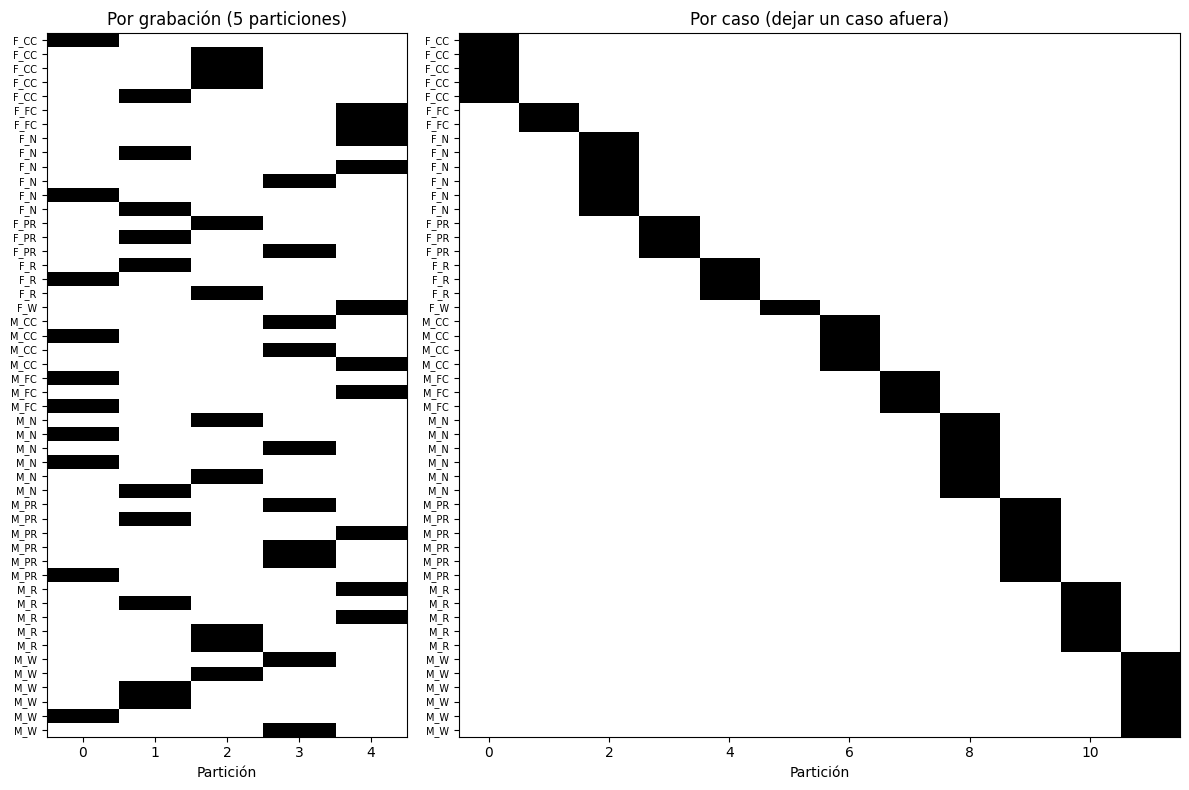

In [6]:
df, X, y, caso = datos["LS"]
orden = np.argsort(caso, kind="stable")
esquemas = {"Por grabación (5 particiones)": list(StratifiedKFold(5, shuffle=True, random_state=0).split(X, y)),
            "Por caso (dejar un caso afuera)": list(LeaveOneGroupOut().split(X, y, caso))}

fig, axes = plt.subplots(1, 2, figsize=(12, 8), gridspec_kw={"width_ratios": [1, 2]})
for ax, (nombre, particiones) in zip(axes, esquemas.items()):
    matriz = np.zeros((len(y), len(particiones)))
    for j, (_, ev) in enumerate(particiones):
        matriz[ev, j] = 1
    ax.imshow(matriz[orden], aspect="auto", cmap="Greys", interpolation="nearest")
    ax.set(title=nombre, xlabel="Partición")
    ax.set_yticks(range(len(y)), labels=caso[orden], fontsize=7)
fig.tight_layout()

A la izquierda, las grabaciones de un mismo caso quedan repartidas en
distintas particiones: en cada partición, el modelo entrena con "hermanas" de
las que evalúa. A la derecha, cada partición evalúa un caso completo.

**¿Por qué "dejar un caso afuera" y no 5 particiones por caso?** Porque hay
solo **2 casos normales** (`F_N` y `M_N`). Con 5 particiones por caso, a
veces los dos normales caen en la misma partición de evaluación, y el modelo
se queda **sin ningún normal para entrenar**. Dejando un caso afuera por vez,
siempre queda el otro normal en entrenamiento.

In [7]:
resultados_caso = {}
for subset, (df, X, y, caso) in datos.items():
    prob = cross_val_predict(modelo(), X, y, cv=LeaveOneGroupOut(), groups=caso, method="predict_proba")[:, 1]
    resultados_caso[subset] = roc_auc_score(y, prob)
    print(f"{subset}: {len(set(caso))} casos ({len(set(caso[y == 0]))} normales) -> "
          f"AUC por caso = {resultados_caso[subset]:.3f}   (por grabación, media: {np.mean(aucs_grabacion[subset]):.3f})")

LS: 12 casos (2 normales) -> AUC por caso = 0.967   (por grabación, media: 0.998)
HS: 19 casos (2 normales) -> AUC por caso = 0.610   (por grabación, media: 0.711)


En los dos subconjuntos el AUC por caso es más bajo. La tentación es decir:
"la diferencia es el **optimismo** de validar por grabación, causado por la
fuga". Pero **los dos esquemas difieren en más de una cosa**:
- en la validación por caso, cada partición deja afuera un **grupo entero de
  una sola clase** (por ejemplo, los 6 normales de `F_N` juntos). Eso
  desbalancea el entrenamiento justo en contra del grupo que se evalúa, y
  tiende a bajar el AUC **aunque no haya ninguna fuga**;
- la cantidad de particiones y el tamaño del entrenamiento también cambian.

Para saber cuánto de la diferencia es **fuga** y cuánto es **la forma de
validar**, hace falta un experimento de control.

## 5. Experimento de control: pseudo-casos al azar

Armamos **pseudo-casos**: grupos al azar con **el mismo tamaño y la misma
clase** que los casos reales, pero formados por grabaciones que **no son
hermanas** (se sortean dentro de cada clase). Después validamos exactamente
igual: dejando un pseudo-caso afuera por vez.

Así, los dos esquemas son idénticos en todo (cantidad de particiones, tamaño
de los grupos, clase de cada grupo) **salvo en una cosa**: si las grabaciones
de un grupo vienen o no del mismo caso. Entonces:
- si el AUC con casos reales es **más bajo** que con pseudo-casos, la
  diferencia es la **fuga**;
- si son **parecidos**, la caída respecto de la validación por grabación no
  se debe a la fuga, sino a la forma de validar.

Repetimos el sorteo de pseudo-casos 20 veces para ver su variabilidad.

In [8]:
def pseudo_casos(caso, y, rng):
    """Grupos al azar con los mismos tamaños y la misma clase que los casos reales."""
    nuevo = np.empty(len(caso), dtype=object)
    for clase in [0, 1]:
        indices = rng.permutation(np.where(y == clase)[0])
        tamanios = pd.Series(caso[y == clase]).value_counts().values
        inicio = 0
        for j, t in enumerate(tamanios):
            nuevo[indices[inicio:inicio + t]] = f"pseudo_{clase}_{j}"
            inicio += t
    return nuevo


aucs_pseudo = {}
for subset, (df, X, y, caso) in datos.items():
    rng = np.random.default_rng(0)
    aucs_pseudo[subset] = [
        roc_auc_score(y, cross_val_predict(modelo(), X, y, cv=LeaveOneGroupOut(),
                                           groups=pseudo_casos(caso, y, rng), method="predict_proba")[:, 1])
        for _ in range(REPETICIONES)]

resumen = pd.DataFrame({
    subset: {"por grabación (media de 20 sorteos)": np.mean(aucs_grabacion[subset]),
             "por pseudo-caso (media de 20 sorteos)": np.mean(aucs_pseudo[subset]),
             "por pseudo-caso: mínimo": np.min(aucs_pseudo[subset]),
             "por pseudo-caso: máximo": np.max(aucs_pseudo[subset]),
             "por caso real": resultados_caso[subset]}
    for subset in datos}).T
print(resumen.round(3).to_string())

    por grabación (media de 20 sorteos)  por pseudo-caso (media de 20 sorteos)  por pseudo-caso: mínimo  por pseudo-caso: máximo  por caso real
LS                                0.998                                  0.991                    0.969                    1.000          0.967
HS                                0.711                                  0.621                    0.385                    0.764          0.610


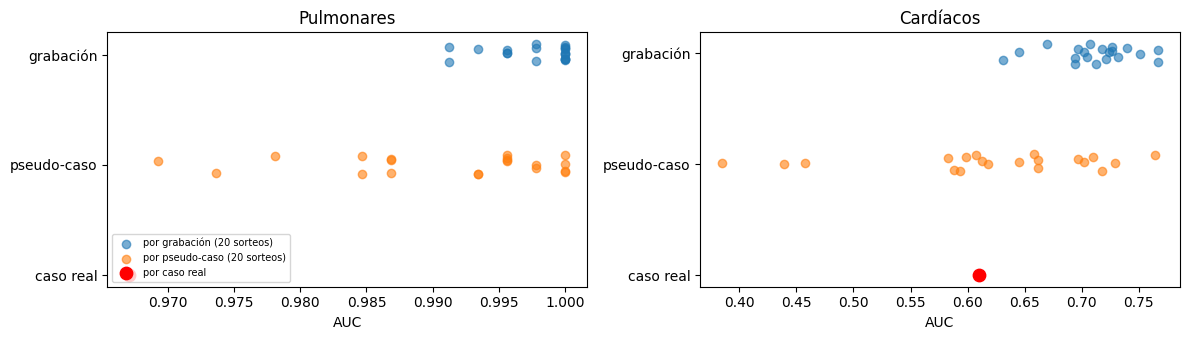

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, subset in zip(axes, datos):
    ax.scatter(aucs_grabacion[subset], np.full(REPETICIONES, 2) + np.random.uniform(-0.1, 0.1, REPETICIONES),
               alpha=0.6, label="por grabación (20 sorteos)")
    ax.scatter(aucs_pseudo[subset], np.full(REPETICIONES, 1) + np.random.uniform(-0.1, 0.1, REPETICIONES),
               alpha=0.6, label="por pseudo-caso (20 sorteos)")
    ax.scatter([resultados_caso[subset]], [0], color="red", s=80, label="por caso real")
    ax.set(yticks=[0, 1, 2], yticklabels=["caso real", "pseudo-caso", "grabación"], xlabel="AUC",
           title={"LS": "Pulmonares", "HS": "Cardíacos"}[subset])
axes[0].legend(fontsize=7, loc="lower left")
fig.tight_layout()

**Cómo leerlo:**
- **Pulmonares:** el caso real queda **por debajo de todos** los
  pseudo-casos. Hay una fuga real, pero chica: unos 2 puntos de AUC.
- **Cardíacos:** el caso real cae **en medio** de los pseudo-casos. La caída
  respecto de la validación por grabación **no se debe a la fuga** entre
  grabaciones del mismo caso, sino a la forma de validar (dejar afuera grupos
  enteros de una clase). Además, los pseudo-casos varían muchísimo de un
  sorteo a otro: el resultado cardíaco es muy inestable.

**Qué cambia para la tesis.** La versión anterior medía el "optimismo" como
la diferencia entre validar por grabación y validar por caso, y la atribuía a
la fuga. El control muestra que, al menos para la regresión logística, esa
diferencia **mezcla dos cosas**: una fuga pequeña (en pulmonares) y el efecto
del esquema de validación (en los dos). Esto también respalda la decisión de
usar la validación por grabación como principal: con este modelo, la fuga
entre grabaciones del mismo caso es chica. En la notebook de comparación
vamos a aplicar el mismo control a todos los modelos, porque otros modelos
podrían aprovechar más la fuga.

## 6. Una palabra sobre los hiperparámetros

Los modelos tienen parámetros que se eligen antes de entrenar (por ejemplo,
la profundidad de un árbol). Si se eligen probando varios valores y quedándose
con el que mejor AUC da **en la misma validación con la que después se
reporta**, el AUC sale optimista: es la misma trampa que elegir el filtro o
el umbral mirando los resultados (Cawley y Talbot, 2010, en tu bibliografía).

Hay dos formas honestas:
- **fijar los hiperparámetros de antemano**, con valores razonables y
  conservadores (lo que hace la tesis, Tabla 7.1);
- **validación cruzada anidada:** una validación "interna", solo con los
  datos de entrenamiento de cada partición, elige los hiperparámetros, y la
  "externa" mide el desempeño. Es más costosa y, con tan pocos datos, la
  elección interna también es inestable.

## 7. Tu turno

Probá la validación por grabación con otra cantidad de particiones (por
ejemplo 3 u 8). ¿Cambia el AUC medio? ¿Y la variabilidad entre sorteos?

Límite: la cantidad de particiones no puede superar la cantidad de normales
(9 en cardíacos, 12 en pulmonares). Si no, alguna partición se queda sin
normales y scikit-learn avisa con una advertencia.

In [10]:
SUBSET, K = "HS", 3

df, X, y, caso = datos[SUBSET]
v = [roc_auc_score(y, cross_val_predict(modelo(), X, y, cv=StratifiedKFold(K, shuffle=True, random_state=s),
                                        method="predict_proba")[:, 1]) for s in range(REPETICIONES)]
print(f"{SUBSET}, {K} particiones: AUC media {np.mean(v):.3f}, de {np.min(v):.3f} a {np.max(v):.3f}")

HS, 3 particiones: AUC media 0.712, de 0.553 a 0.827


## Preguntas de control

1. ¿Por qué el AUC sobre los datos de entrenamiento da casi 1 aunque el
   modelo no sirva tanto? ¿Cómo se llama ese fenómeno?
2. Explicá la validación cruzada estratificada de 5 particiones. ¿Por qué
   "estratificada" es importante con 12 normales?
3. ¿Qué son las predicciones *out-of-fold* y por qué calculamos un solo AUC
   con todas en vez de promediar el AUC de cada partición?
4. ¿Por qué repetimos la validación con distintas semillas? ¿Qué nos dice el
   rango de AUC en cardíacos?
5. ¿Cómo se calcula un intervalo de confianza por bootstrap? ¿Qué significa
   que el intervalo cardíaco sea ancho?
6. ¿Qué diferencia hay entre validar por grabación y por caso? ¿Por qué en la
   validación por caso dejamos afuera un caso por vez y no usamos 5 particiones?
7. ¿Qué es el experimento de los pseudo-casos y qué mostró en cada
   subconjunto? ¿Por qué cambia la interpretación del "optimismo"?

## Respuestas a las preguntas de control

*(Intentá responder antes de leer.)*

**1.** Porque con 105 features y 50 grabaciones el modelo puede memorizar
cada grabación de entrenamiento: es **sobreajuste**. Evaluar con los mismos
datos es como tomar un examen con las preguntas que el alumno ya estudió.

**2.** Se dividen las grabaciones en 5 grupos; se entrena con 4 y se evalúa
con el quinto, rotando hasta que cada grabación fue evaluada una vez por un
modelo que no la vio. "Estratificada" significa que cada grupo mantiene la
proporción de clases; con 12 normales, sin estratificar un grupo podría
quedarse sin normales y no se podría evaluar bien la especificidad.

**3.** Son las probabilidades que recibe cada grabación del modelo que **no
la usó** para entrenar. Se junta todo en un solo AUC porque cada partición
tiene solo 2 o 3 normales, y un AUC con tan pocos normales es muy inestable.

**4.** Porque cómo se reparten las grabaciones es un sorteo, y con pocos
datos el resultado depende de ese sorteo. En cardíacos, el mismo modelo da
entre ~0,63 y ~0,77 según el sorteo: un único número esconde esa
incertidumbre.

**5.** Se toman 50 grabaciones al azar con reposición, se calcula el AUC, se
repite 2000 veces y se toman los percentiles 2,5 y 97,5. Un intervalo ancho
significa que, con otra muestra parecida, el AUC podría ser muy distinto; si
llega cerca de 0,5, no podemos descartar que el modelo no sirva. (Y si el AUC
de la muestra es exactamente 1, el bootstrap da [1–1] y no informa nada.)

**6.** Por grabación, las grabaciones de un mismo caso pueden quedar en
entrenamiento y en evaluación a la vez, y el modelo puede reconocer el caso
(fuga). Por caso, todas las grabaciones de un caso van juntas. Se deja un
caso afuera por vez porque hay solo 2 casos normales: con 5 particiones, a
veces los dos caerían en evaluación y el modelo no tendría normales para
entrenar.

**7.** Se arman grupos al azar con el mismo tamaño y la misma clase que los
casos reales, pero con grabaciones que no son "hermanas", y se valida igual.
La única diferencia con la validación por caso es si hay fuga. En pulmonares,
el caso real dio por debajo de todos los pseudo-casos: hay una fuga, pero
chica (~0,02). En cardíacos dio en medio: la caída no se debe a la fuga, sino
a la forma de validar. Por eso la diferencia "por grabación − por caso" no se
puede interpretar directamente como optimismo por fuga.